# Этап 05. Экономические признаки муниципалитетов: аудит и представления

**Цель:** проверить подготовленные матрицы этапа 04, сравнить исходные композиционные доли с CLR и определить допустимые пространства признаков для будущей динамической сети. 

Входы: месячная матрица СберИндекса, годовые уровни БДМО и отдельно межгодовые изменения. Сначала проводим эмпирические проверки; выбор модели на этом этапе не предопределён.

## 1. Происхождение данных и проверка файлов

Этап 01 определил шесть категорий: `share_food`, `share_health`, `share_marketplace`, `share_dining`, `share_transport`, `share_other`. Этап 04 сохранил 24-месячный вектор и восемь годовых характеристик за два года. Отсутствующие годовые значения не заполняем; порядок муниципалитетов должен совпадать.

Имена годовых показателей, единицы измерения и точная структура файлов **не предполагаются**: ниже они извлекаются из файлов и словаря этапа 04.

In [1]:
from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT))

from src.feature_analysis import (
    SHARES,
    parse_dynamic_columns,
    monthly_view,
    composition_diagnostics,
    transform_shares,
    window_view,
    sampled_distances,
    annual_summary,
    verify_index,
    infer_annual_columns,
)

config = json.loads(
    (ROOT / "configs" / "bdmo.json").read_text(encoding="utf-8")
)

feature_dir = ROOT / "outputs" / "bdmo_v3" / "features"

paths = {
    "dynamic": feature_dir / "X_consumer_24m.parquet",
    "annual": feature_dir / "X_annual_core_raw.parquet",
    "delta": feature_dir / "X_annual_core_delta.parquet",
}

for name, path in paths.items():
    if not path.is_file():
        raise FileNotFoundError(
            f"Не найден файл {name}: {path}"
        )

display(pd.DataFrame([
    {
        "matrix": name,
        "path": str(path.relative_to(ROOT)),
        "bytes": path.stat().st_size,
    }
    for name, path in paths.items()
]))

X_dynamic = pd.read_parquet(paths["dynamic"])
X_annual = pd.read_parquet(paths["annual"])
X_delta = pd.read_parquet(paths["delta"])

verify_index(X_dynamic, X_annual, X_delta)

display(pd.DataFrame([
    {
        "matrix": "X_dynamic",
        "rows": X_dynamic.shape[0],
        "columns": X_dynamic.shape[1],
    },
    {
        "matrix": "X_annual",
        "rows": X_annual.shape[0],
        "columns": X_annual.shape[1],
    },
    {
        "matrix": "X_delta",
        "rows": X_delta.shape[0],
        "columns": X_delta.shape[1],
    },
]))

,matrix,path,bytes
0,dynamic,outputs/bdmo_v3/features/X_consumer_24m.parquet,2833526
1,annual,outputs/bdmo_v3/features/X_annual_core_raw.par...,271191
2,delta,outputs/bdmo_v3/features/X_annual_core_delta.p...,137602


,matrix,rows,columns
0,X_dynamic,2016,144
1,X_annual,2016,16
2,X_delta,2016,8


## 2. Точная структура месячного пространства

Пусть $x_{i,t,k}$ — доля расходов муниципалитета $i$ в месяце $t$ по категории $k$ ($k=1,\dots,6$). Для корректной композиции $x_{i,t,k}\geq 0$ и $\sum_{k=1}^6 x_{i,t,k}=1$. Вектор $X_{i,t}=(x_{i,t,1},\dots,x_{i,t,6})$ представляет **один месяц**, а 144-мерный вектор — **полную траекторию** 24 месяцев, непригодную как атрибут раннего месяца.

Структура колонок проверяется по их действительным именам: каждый месяц должен иметь ровно шесть указанных категорий.

In [2]:
mapping=parse_dynamic_columns(X_dynamic)
months=sorted({p for p,_ in mapping})
print('Шесть базовых показателей:',list(SHARES))
print('Месяцы:',[str(p) for p in months]); print('Число колонок:',len(mapping))
display(pd.DataFrame([{'month':str(p),'category':c,'source_column':str(mapping[p,c])} for p in months for c in SHARES]).head(12))
display(monthly_view(X_dynamic,mapping,months[0]).iloc[:5].round(4))
checks=composition_diagnostics(X_dynamic,mapping)
display(checks)
assert checks[['missing_cells','negative_cells','over_one_cells','nonfinite_cells']].to_numpy().sum()==0, 'Ошибка качества долей: требуется исследование источника'
assert checks.max_sum_error.max()<1e-6, 'Суммы долей должны быть равны единице' 

Шесть базовых показателей: ['share_food', 'share_health', 'share_marketplace', 'share_dining', 'share_transport', 'share_other']
Месяцы: ['2023-01', '2023-02', '2023-03', '2023-04', '2023-05', '2023-06', '2023-07', '2023-08', '2023-09', '2023-10', '2023-11', '2023-12', '2024-01', '2024-02', '2024-03', '2024-04', '2024-05', '2024-06', '2024-07', '2024-08', '2024-09', '2024-10', '2024-11', '2024-12']
Число колонок: 144


,month,category,source_column
0,2023-01,share_food,share_food__2023-01
1,2023-01,share_health,share_health__2023-01
2,2023-01,share_marketplace,share_marketplace__2023-01
3,2023-01,share_dining,share_dining__2023-01
4,2023-01,share_transport,share_transport__2023-01
5,2023-01,share_other,share_other__2023-01
6,2023-02,share_food,share_food__2023-02
7,2023-02,share_health,share_health__2023-02
8,2023-02,share_marketplace,share_marketplace__2023-02
9,2023-02,share_dining,share_dining__2023-02


,share_food,share_health,share_marketplace,share_dining,share_transport,share_other
territory_id,,,,,,
1,0.3564,0.0589,0.1161,0.0529,0.0796,0.3361
2,0.3599,0.0707,0.1234,0.0657,0.0902,0.2902
3,0.4205,0.0533,0.1274,0.0225,0.0585,0.3179
4,0.4067,0.0662,0.1194,0.0242,0.0791,0.3044
5,0.4416,0.0618,0.1261,0.0198,0.0781,0.2725


,missing_cells,zero_cells,negative_cells,over_one_cells,nonfinite_cells,max_sum_error,min_share,max_share
month,,,,,,,,
2023-01,0,0,0,0,0,2.220446e-16,0.002223,0.632647
2023-02,0,0,0,0,0,2.220446e-16,0.002534,0.650031
2023-03,0,0,0,0,0,2.220446e-16,0.004423,0.634465
2023-04,0,0,0,0,0,2.220446e-16,0.001982,0.664595
2023-05,0,0,0,0,0,2.220446e-16,0.001938,0.676887
2023-06,0,0,0,0,0,2.220446e-16,0.001629,0.699537
2023-07,0,0,0,0,0,2.220446e-16,0.003913,0.723316
2023-08,0,0,0,0,0,2.220446e-16,0.003189,0.644940
2023-09,0,0,0,0,0,2.220446e-16,0.003353,0.683384


## 3. Динамика, сезонность, различия территорий

Средняя доля по муниципалитетам описывает общий месячный профиль, а межмуниципальный IQR показывает пространственную неоднородность. Повторяющиеся календарные месяцы **могут** отражать сезонность, однако лишь два года не позволяют отделить сезонность от тренда и единичных шоков с высокой точностью. Корреляции долей интерпретируем осторожно: из-за ограничения суммы единицей часть отрицательных корреляций индуцирована математически.

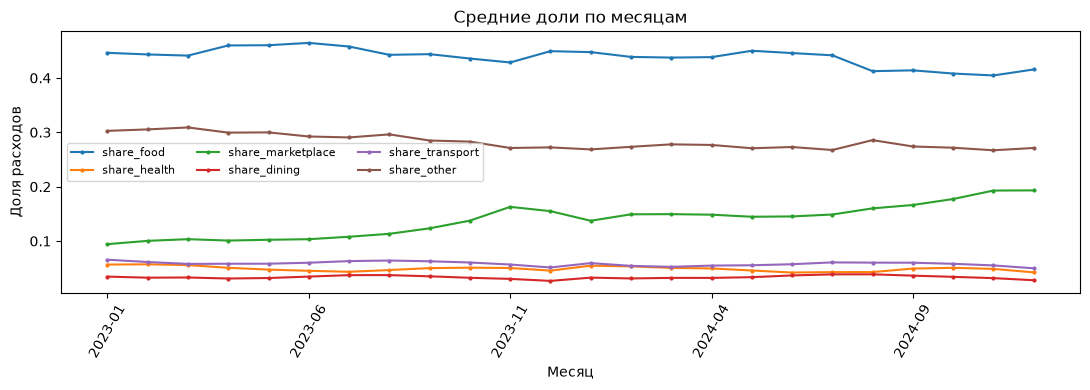

Средний IQR по категориям:


,IQR
share_food,0.088259
share_health,0.011307
share_marketplace,0.044532
share_dining,0.031093
share_transport,0.020810
share_other,0.073269


Корреляции категорий за последний месяц:


,share_food,share_health,share_marketplace,share_dining,share_transport,share_other
share_food,1.000,-0.468,0.211,-0.834,-0.570,-0.757
share_health,-0.468,1.000,-0.049,0.444,0.362,0.160
share_marketplace,0.211,-0.049,1.000,-0.508,-0.331,-0.719
share_dining,-0.834,0.444,-0.508,1.000,0.576,0.737
share_transport,-0.570,0.362,-0.331,0.576,1.000,0.379
share_other,-0.757,0.160,-0.719,0.737,0.379,1.000


Распределения для первого и последнего месяца:


count   mean    std    min    25%    50%    75%  \
period category                                                              
start  share_food         2016.0  0.446  0.063  0.237  0.409  0.453  0.487   
       share_health       2016.0  0.057  0.009  0.013  0.052  0.057  0.062   
       share_marketplace  2016.0  0.094  0.027  0.017  0.076  0.093  0.112   
       share_dining       2016.0  0.035  0.021  0.002  0.018  0.028  0.047   
       share_transport    2016.0  0.066  0.014  0.007  0.057  0.066  0.074   
       share_other        2016.0  0.303  0.048  0.151  0.270  0.303  0.335   
end    share_food         2016.0  0.416  0.060  0.233  0.381  0.424  0.455   
       share_health       2016.0  0.042  0.008  0.008  0.037  0.042  0.048   
       share_marketplace  2016.0  0.193  0.041  0.021  0.167  0.192  0.220   
       share_dining       2016.0  0.028  0.020  0.002  0.012  0.021  0.039   
       share_transport    2016.0  0.050  0.013  0.011  0.040  0.049  0.060   
       share_other        2016.0  0.271  0.053  0.119  0.234  0.270  0.307   

                            max  
period category                  
start  share_food         0.633  
       share_health       0.107  
       share_marketplace  0.196  
       share_dining       0.103  
       share_transport    0.149  
       share_other        0.543  
end    share_food         0.613  
       share_health       0.073  
       share_marketplace  0.353  
       share_dining       0.104  
       share_transport    0.116  
       share_other        0.464

In [3]:
monthly={str(p):monthly_view(X_dynamic,mapping,p) for p in months}
mean_month=pd.DataFrame({m:x.mean() for m,x in monthly.items()}).T
q_spread=pd.DataFrame({m:(x.quantile(.75)-x.quantile(.25)) for m,x in monthly.items()}).T
fig,ax=plt.subplots(figsize=(11,4));mean_month.plot(ax=ax,marker='o',markersize=2)
ax.set(title='Средние доли по месяцам',ylabel='Доля расходов',xlabel='Месяц');ax.legend(ncol=3,fontsize=8);plt.xticks(rotation=60);plt.tight_layout();plt.show()
print('Средний IQR по категориям:')
display(q_spread.mean().rename('IQR').to_frame())
print('Корреляции категорий за последний месяц:')
display(monthly[str(months[-1])].corr().round(3))
print('Распределения для первого и последнего месяца:')
display(pd.concat({'start':monthly[str(months[0])].describe().T,'end':monthly[str(months[-1])].describe().T},names=['period','category']).round(3))

## 4. Годовые уровни БДМО: смысл, пропуски и зависимость

Для восьми годовых показателей оцениваем покрытие, медиану, квартили, асимметрию и долю наблюдений за границами $[Q_1-1.5\,IQR,\;Q_3+1.5\,IQR]$, где $IQR=Q_3-Q_1$.

Ожидаемые экономические смыслы из отбора этапа 02: зарплата (денежная оплата труда), формальная занятость (интенсивность), отчитывающиеся организации (плотность), прибыльные организации (доля), инвестиции на жителя, торговая площадь на жителя, плотность населения, освещённые улицы (доля).

Все колонки X_annual:


,column,year,base_indicator
0,wage__2023,2023,wage
1,employment_per_1000__2023,2023,employment_per_1000
2,reporting_companies_per_1000__2023,2023,reporting_companies_per_1000
3,profitable_share__2023,2023,profitable_share
4,investment_total_per_capita__2023,2023,investment_total_per_capita
5,shop_floor_per_capita__2023,2023,shop_floor_per_capita
6,population_density__2023,2023,population_density
7,lit_street_share__2023,2023,lit_street_share
8,wage__2024,2024,wage
9,employment_per_1000__2024,2024,employment_per_1000


Словарь этапа 04:


,feature,role,view,source,definition
0,wage,primary,labor,8423007,Уровень оплаты труда дополняет структуру потре...
1,employment_per_1000,primary,labor,8423005,После конверсии единиц / population_mean × 1000
2,reporting_companies_per_1000,primary,business,8090001,После конверсии единиц / population_jan × 1000
3,profitable_share,primary,business,8090008,Доля прибыльных организаций: интенсивность без...
4,investment_total_per_capita,primary,investment,8109001,После конверсии единиц / population_mean × 1
5,shop_floor_per_capita,primary,retail_supply,8002002,После конверсии единиц / population_jan × 1
6,population_density,primary,demography,8112027 / 8006001,Человек на км²: население на 1 января / (площа...
7,lit_street_share,primary,infrastructure,8006003 / 8006007,"Доля освещённой протяжённости улиц, %; вне [0,..."


,missing_fraction,min,p25,median,p75,max,iqr_outlier_fraction,skew
wage__2023,0.000,29141.1,42284.175,51251.6,72907.75,422447.9,0.078,2.39
employment_per_1000__2023,0.041,10.376,134.709,172.866,232.536,3733.516,0.077,6.776
reporting_companies_per_1000__2023,0.003,0.63,3.372,5.006,8.973,219.516,0.1,6.191
profitable_share__2023,0.000,36.4,75.0,80.0,83.3,100.0,0.041,-1.092
investment_total_per_capita__2023,0.045,553.396,17605.733,38908.752,101904.562,29121284.876,0.109,14.046
shop_floor_per_capita__2023,0.069,0.0,0.518,0.69,0.902,14.474,0.045,10.965
population_density__2023,0.003,0.014,4.635,12.237,147.09,30569.762,0.224,3.506
lit_street_share__2023,0.051,0.466,48.303,71.217,88.98,100.0,0.0,-0.537
wage__2024,0.007,34906.1,50409.5,61643.1,86680.3,405587.4,0.071,2.185
employment_per_1000__2024,0.082,9.362,136.409,174.939,235.438,3742.004,0.073,6.588


Корреляции Спирмена (попарно доступные наблюдения):


,wage__2023,employment_per_1000__2023,reporting_companies_per_1000__2023,profitable_share__2023,investment_total_per_capita__2023,shop_floor_per_capita__2023,population_density__2023,lit_street_share__2023,wage__2024,employment_per_1000__2024,reporting_companies_per_1000__2024,profitable_share__2024,investment_total_per_capita__2024,shop_floor_per_capita__2024,population_density__2024,lit_street_share__2024
wage__2023,1.00,0.50,0.60,0.04,0.58,0.18,0.37,0.30,0.99,0.49,0.59,0.04,0.60,0.19,0.36,0.31
employment_per_1000__2023,0.50,1.00,0.32,-0.03,0.61,0.35,0.01,0.10,0.50,0.99,0.31,-0.06,0.61,0.35,0.01,0.12
reporting_companies_per_1000__2023,0.60,0.32,1.00,0.05,0.40,0.32,0.58,0.34,0.61,0.32,0.99,0.07,0.43,0.33,0.57,0.34
profitable_share__2023,0.04,-0.03,0.05,1.00,-0.00,0.07,0.28,0.08,0.05,-0.01,0.06,0.70,0.02,0.07,0.29,0.07
investment_total_per_capita__2023,0.58,0.61,0.40,-0.00,1.00,0.21,0.20,0.17,0.59,0.63,0.40,-0.04,0.88,0.20,0.19,0.17
shop_floor_per_capita__2023,0.18,0.35,0.32,0.07,0.21,1.00,0.23,0.11,0.18,0.34,0.31,0.04,0.19,0.97,0.23,0.10
population_density__2023,0.37,0.01,0.58,0.28,0.20,0.23,1.00,0.35,0.38,0.03,0.57,0.29,0.24,0.24,1.00,0.35
lit_street_share__2023,0.30,0.10,0.34,0.08,0.17,0.11,0.35,1.00,0.30,0.11,0.33,0.10,0.17,0.10,0.35,0.98
wage__2024,0.99,0.50,0.61,0.05,0.59,0.18,0.38,0.30,1.00,0.50,0.60,0.05,0.62,0.19,0.37,0.30
employment_per_1000__2024,0.49,0.99,0.32,-0.01,0.63,0.34,0.03,0.11,0.50,1.00,0.32,-0.05,0.63,0.34,0.03,0.13


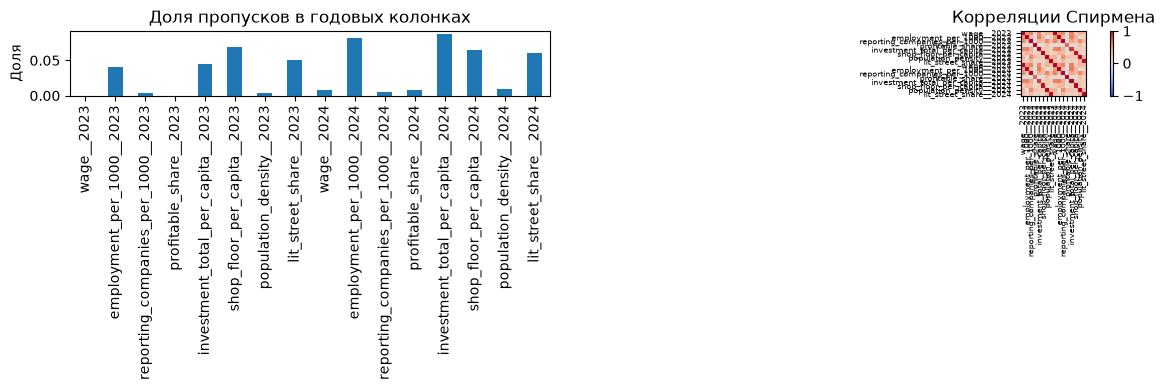

Кандидаты содержательного дублирования — пары |rho|≥0.8 (не удаляются автоматически):


,feature_1,feature_2,rho
0,wage__2023,wage__2024,0.990
1,employment_per_1000__2023,employment_per_1000__2024,0.990
2,reporting_companies_per_1000__2023,reporting_companies_per_1000__2024,0.994
3,investment_total_per_capita__2023,investment_total_per_capita__2024,0.879
4,shop_floor_per_capita__2023,shop_floor_per_capita__2024,0.973
5,population_density__2023,population_density__2024,0.997
6,lit_street_share__2023,lit_street_share__2024,0.983


In [4]:
annual_structure=infer_annual_columns(X_annual.columns)
print('Все колонки X_annual:');display(annual_structure)
dictionary_path=paths['annual'].parent/'feature_dictionary.csv'
if dictionary_path.exists():
    feature_dictionary=pd.read_csv(dictionary_path)
    print('Словарь этапа 04:');display(feature_dictionary.head(25))
else:
    print('ВНИМАНИЕ: feature_dictionary.csv отсутствует — экономические единицы требуют проверки в источнике.')
annual_stats=annual_summary(X_annual)
display(annual_stats.round(3))
print('Корреляции Спирмена (попарно доступные наблюдения):')
annual_corr=X_annual.corr(method='spearman',min_periods=100)
display(annual_corr.round(2))
fig,axs=plt.subplots(1,2,figsize=(12,4))
annual_stats.missing_fraction.plot.bar(ax=axs[0],title='Доля пропусков в годовых колонках');axs[0].set_ylabel('Доля')
im=axs[1].imshow(annual_corr.to_numpy(),vmin=-1,vmax=1,cmap='coolwarm');axs[1].set_title('Корреляции Спирмена');axs[1].set_xticks(range(len(X_annual.columns)));axs[1].set_yticks(range(len(X_annual.columns)))
axs[1].set_xticklabels(map(str,X_annual.columns),rotation=90,fontsize=6);axs[1].set_yticklabels(map(str,X_annual.columns),fontsize=6)
fig.colorbar(im,ax=axs[1],fraction=.04);plt.tight_layout();plt.show()
print('Кандидаты содержательного дублирования — пары |rho|≥0.8 (не удаляются автоматически):')
pairs=[(str(annual_corr.index[i]),str(annual_corr.columns[j]),round(float(annual_corr.iat[i,j]),3)) for i in range(len(annual_corr)) for j in range(i+1,len(annual_corr)) if pd.notna(annual_corr.iat[i,j]) and abs(annual_corr.iat[i,j])>=.8]
display(pd.DataFrame(pairs,columns=['feature_1','feature_2','rho']).head(25))

## 5. Межгодовая динамика и связь с уровнями

Если годовой показатель $a_{i,k,y}$ определён в обоих годах, абсолютное изменение равно $\Delta a_{i,k}=a_{i,k,2024}-a_{i,k,2023}$. Относительное изменение при $a_{i,k,2023}\ne0$: $r_{i,k}=(a_{i,k,2024}-a_{i,k,2023})/|a_{i,k,2023}|$; его вычислять и интерпретировать можно только с экономическим обоснованием знака и нулевых значений.

Уровни и их изменения математически зависимы. Автоматическое объединение `X_annual` и `X_delta` повторно взвешивает одни исходные показатели; масштабы (рубли, проценты, кв. метры и др.) также различаются.

In [5]:
print("Все колонки X_delta и размеры:")
display(infer_annual_columns(X_delta.columns))
print(X_delta.shape)

delta_stats = annual_summary(X_delta)
display(delta_stats.round(3))

for stats, X in [
    (annual_stats, X_annual),
    (delta_stats, X_delta),
]:
    if "iqr" not in stats.columns:
        stats["iqr"] = (
            X.quantile(0.75) - X.quantile(0.25)
        ).reindex(stats.index)

print("Сравнение медианных значений и межквартильных размахов:")

comparison = pd.concat(
    {
        "annual": annual_stats[["median", "iqr"]],
        "delta": delta_stats[["median", "iqr"]],
    },
    names=["view", "feature"],
)

display(comparison.round(3))

Все колонки X_delta и размеры:


,column,year,base_indicator
0,wage__delta_2023_2024,НЕ РАСПОЗНАН,wage__delta
1,employment_per_1000__delta_2023_2024,НЕ РАСПОЗНАН,employment_per_1000__delta
2,reporting_companies_per_1000__delta_2023_2024,НЕ РАСПОЗНАН,reporting_companies_per_1000__delta
3,profitable_share__delta_2023_2024,НЕ РАСПОЗНАН,profitable_share__delta
4,investment_total_per_capita__delta_2023_2024,НЕ РАСПОЗНАН,investment_total_per_capita__delta
5,shop_floor_per_capita__delta_2023_2024,НЕ РАСПОЗНАН,shop_floor_per_capita__delta
6,population_density__delta_2023_2024,НЕ РАСПОЗНАН,population_density__delta
7,lit_street_share__delta_2023_2024,НЕ РАСПОЗНАН,lit_street_share__delta


(2016, 8)


,missing_fraction,min,p25,median,p75,max,iqr_outlier_fraction,skew
wage__delta_2023_2024,0.007,-51035.2,7616.6,9810.8,13670.6,104086.5,0.059,2.35
employment_per_1000__delta_2023_2024,0.085,-416.243,-3.469,-0.278,3.571,401.739,0.119,0.243
reporting_companies_per_1000__delta_2023_2024,0.006,-12.026,-0.175,-0.014,0.168,8.726,0.079,-2.698
profitable_share__delta_2023_2024,0.008,-40.0,-2.6,-0.2,2.1,36.5,0.089,-0.219
investment_total_per_capita__delta_2023_2024,0.090,-5917692.871,-4511.886,5386.374,26762.409,13660410.604,0.161,14.545
shop_floor_per_capita__delta_2023_2024,0.085,-1.744,-0.001,0.011,0.031,18.454,0.116,39.228
population_density__delta_2023_2024,0.013,-1237.513,-0.225,-0.085,-0.017,4053.649,0.279,20.71
lit_street_share__delta_2023_2024,0.060,-48.23,0.0,0.0,0.705,90.535,0.234,4.637


Сравнение медианных значений и межквартильных размахов:


median         iqr
view   feature                                                             
annual wage__2023                                       51251.6   30623.575
       employment_per_1000__2023                        172.866      97.828
       reporting_companies_per_1000__2023                 5.006       5.602
       profitable_share__2023                              80.0         8.3
       investment_total_per_capita__2023              38908.752   84298.829
       shop_floor_per_capita__2023                         0.69       0.384
       population_density__2023                          12.237     142.455
       lit_street_share__2023                            71.217      40.677
       wage__2024                                       61643.1     36270.8
       employment_per_1000__2024                        174.939      99.029
       reporting_companies_per_1000__2024                 5.011       5.699
       profitable_share__2024                              79.6         8.0
       investment_total_per_capita__2024              46790.887  102657.537
       shop_floor_per_capita__2024                        0.703       0.392
       population_density__2024                          12.064     130.236
       lit_street_share__2024                            71.749      40.187
delta  wage__delta_2023_2024                             9810.8      6054.0
       employment_per_1000__delta_2023_2024              -0.278       7.041
       reporting_companies_per_1000__delta_2023_2024     -0.014       0.343
       profitable_share__delta_2023_2024                   -0.2         4.7
       investment_total_per_capita__delta_2023_2024    5386.374   31274.295
       shop_floor_per_capita__delta_2023_2024             0.011       0.032
       population_density__delta_2023_2024               -0.085       0.207
       lit_street_share__delta_2023_2024                    0.0       0.705

## 6. Композиционные доли: исходные значения и CLR

Для строго положительной композиции $x=(x_1,\ldots,x_6)$ преобразование centered log-ratio:

$$\operatorname{clr}(x)_k=\ln x_k-\frac{1}{6}\sum_{j=1}^{6}\ln x_j=\ln\frac{x_k}{g(x)},\qquad g(x)=\left(\prod_{j=1}^6 x_j\right)^{1/6}.$$

CLR принадлежит пятимерной гиперплоскости $\sum_k \operatorname{clr}(x)_k=0$; его евклидово расстояние равно расстоянию Эйчисона между композициями. При нулях логарифм не определён. Для эксперимента используем явную регуляризацию: каждому нулю назначаем $\varepsilon$, ненулевые доли пропорционально сокращаем так, чтобы сумма осталась 1. Сравним несколько $\varepsilon$ при наличии нулей.

$$d_{\mathrm{raw}}(i,j)=\sqrt{\sum_{k=1}^{6}(x_{ik}-x_{jk})^2},\qquad
 d_{\mathrm{CLR}}(i,j)=\sqrt{\sum_{k=1}^{6}(\operatorname{clr}(x_i)_k-\operatorname{clr}(x_j)_k)^2}.$$

Абсолютные величины двух расстояний не сопоставимы по единицам; сравниваем прежде всего ранги и структуру ближних/дальних пар.

Месяц сравнения: 2024-12 нули: 0
Описания дистанций:


,raw_distance,clr_distance
count,12000.0000,12000.0000
mean,0.1147,1.0109
std,0.0642,0.5409
min,0.0048,0.0322
25%,0.0655,0.5890
50%,0.1029,0.9086
75%,0.1511,1.3445
max,0.4158,3.5475


Корреляция рангов (Спирмен): 0.7220540379098876


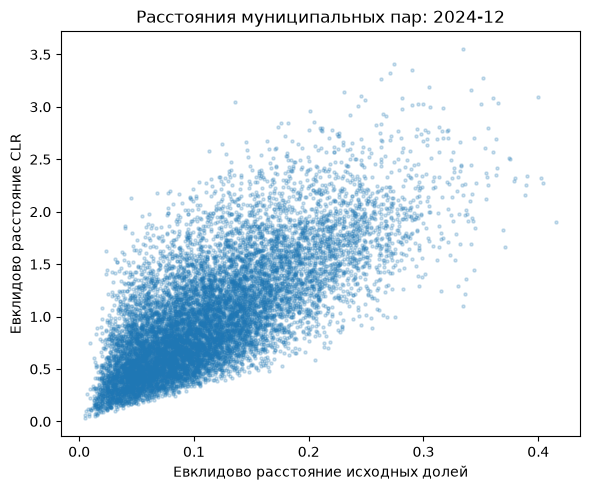

Нулей нет в тестовом месяце; регуляризация не действует.


In [6]:
month=months[-1];raw=monthly_view(X_dynamic,mapping,month)
zero_count=int((raw==0).to_numpy().sum());print('Месяц сравнения:',month,'нули:',zero_count)
floor=1e-6
clr=transform_shares(raw,'clr',zero_floor=floor)
assert raw.index.equals(clr.index)
assert np.allclose(clr.sum(axis=1),0,atol=1e-9)
dist=sampled_distances(raw,clr,sample_pairs=12000,random_state=42)
print('Описания дистанций:');display(dist.describe().round(4))
print('Корреляция рангов (Спирмен):',dist.corr(method='spearman').iloc[0,1])
fig,ax=plt.subplots(figsize=(6,5))
ax.scatter(dist.raw_distance,dist.clr_distance,s=5,alpha=.22)
ax.set(xlabel='Евклидово расстояние исходных долей',ylabel='Евклидово расстояние CLR',title=f'Расстояния муниципальных пар: {month}')
plt.tight_layout();plt.show()
if zero_count:
    print('Чувствительность к регуляризации нулей:')
    display(pd.DataFrame([{'epsilon':eps,'rank_corr_with_raw':sampled_distances(raw,transform_shares(raw,'clr',eps),random_state=42).corr(method='spearman').iloc[0,1]} for eps in [1e-8,1e-6,1e-4]]))
else: print('Нулей нет в тестовом месяце; регуляризация не действует.')

## 7. Время и допустимые пространства признаков

Для месяца $t$: **месячный срез** $X_t\in\mathbb R^{2016\times6}$ (raw или CLR), **окно** $X_{t-L+1:t}\in\mathbb R^{2016\times6L}$, **полная траектория** $X_{1:24}\in\mathbb R^{2016\times144}$. Полную траекторию допустимо использовать лишь для ретроспективной задачи на конец 2024 года, не для сети на дату 2023 года. Реализация `monthly_view` и `window_view` выбирает только месяцы $s\le t$.


In [7]:
t=months[11]
a=monthly_view(X_dynamic,mapping,t)
w=window_view(X_dynamic,mapping,t,length=3,representation='raw')
assert a.index.equals(w.index) and w.shape==(len(X_dynamic),18)
assert all(pd.Period(str(col).split('__')[0],freq='M')<=t for col in w.columns)
print('Пример месяца:',t,'месячная форма:',a.shape,'трёхмесячное окно:',w.shape)
display(w.iloc[:3,:9].round(4))
print('Для сети в t запрещено использовать:',[str(m) for m in months if m>t][:4],'...')

Пример месяца: 2023-12 месячная форма: (2016, 6) трёхмесячное окно: (2016, 18)


,2023-10__share_food,2023-10__share_health,2023-10__share_marketplace,2023-10__share_dining,2023-10__share_transport,2023-10__share_other,2023-11__share_food,2023-11__share_health,2023-11__share_marketplace
territory_id,,,,,,,,,
1,0.3615,0.0559,0.1656,0.0555,0.0761,0.2855,0.3434,0.0522,0.1989
2,0.3456,0.0593,0.2005,0.0514,0.0636,0.2796,0.3461,0.0569,0.2167
3,0.4218,0.0500,0.2039,0.0196,0.0351,0.2696,0.4319,0.0446,0.2293


Для сети в t запрещено использовать: ['2024-01', '2024-02', '2024-03', '2024-04'] ...


## 8. Проверки воспроизводимости и передача следующему этапу

Никакие дополнительные копии трёх матриц не сохраняются. Единственный небольшой артефакт — описание **кандидатных** пространств и проверенных параметров; он не означает выбора победителя. Параметры должны оставаться в общей конфигурации до следующего этапа; минимальные значения эксперимента указаны явно в коде и метаданных.

In [8]:
assert X_dynamic.index.equals(X_annual.index) and X_dynamic.index.equals(X_delta.index)
assert len(months)==24 and len(SHARES)==6
# Явный машинно-читаемый контракт для этапа 06 (не содержит матриц).
metadata={'step':'05','status':'candidates_not_selected','municipalities':len(X_dynamic),
 'months':[str(p) for p in months], 'share_categories':list(SHARES),
 'input_paths':{k:str(v.relative_to(ROOT)) for k,v in paths.items()},
 'candidates':{'monthly':['raw','clr'],'window_lengths_months':[1,3,6],
               'clr_zero_floor':floor,'annual':['interpretation_only','separate_layer_with_time_availability_check'],
               'delta':'separate_diagnostic_only'},'random_state':42,
 'annual_columns':[str(c) for c in X_annual.columns],
 'delta_columns':[str(c) for c in X_delta.columns]}
out=paths['annual'].parent/'feature_space_05.json'
out.write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding='utf-8')
print('Сохранены только метаданные:',out.relative_to(ROOT))
print('Базовые проверки структуры и ограничения будущего времени выполнены.')

Сохранены только метаданные: outputs/bdmo_v3/features/feature_space_05.json
Базовые проверки структуры и ограничения будущего времени выполнены.


## 9. Выводы по результатам выполнения этапа 05

**Статус:** вычислительные ячейки выполнены, сохранённых исключений нет. Данные проверены; пространство для динамической сети определено как набор кандидатов, а не как заранее выбранная модель. Построение графов и кластеризация не проводились.

### 9.1. Качество и экономический смысл потребительской динамики

- Подтверждено **2016 муниципалитетов × 144 признака**: 24 месяца с января 2023 по декабрь 2024 года и ровно шесть категорий: `share_food`, `share_health`, `share_marketplace`, `share_dining`, `share_transport`, `share_other`. Индекс — `territory_id`.
- Во **всех 24 месяцах** отсутствуют пропуски, нули, отрицательные и нечисловые значения, доли больше единицы. Максимальная погрешность суммы шести долей равна $2.22\cdot 10^{-16}$; композиционная структура подтверждена.
- Межмуниципальные различия неравномерны: средний месячный межквартильный размах доли продуктов питания составляет **0.0883**, прочих расходов — **0.0733**, маркетплейсов — **0.0445**, питания вне дома — **0.0311**, транспорта — **0.0208**, здоровья — **0.0113**. Эти величины характеризуют разброс **между муниципалитетами**, а не изменчивость одного муниципалитета во времени.
- Для декабря 2024 года корреляция Пирсона `share_food`–`share_dining` равна **−0.834**, `share_food`–`share_other` — **−0.757**, `share_marketplace`–`share_other` — **−0.719**. Из-за условия суммы долей, равной единице, эти корреляции нельзя напрямую трактовать как причинные экономические связи.
- График средних месячных долей позволяет описывать наблюдаемые колебания 2023–2024 годов, **но двух годовых циклов недостаточно**, чтобы строго отделить устойчивую сезонность от тренда и единичных шоков. На данном этапе сезонная компонента не оценивается отдельной моделью.

### 9.2. Годовые экономические характеристики БДМО

Подтверждены **16 колонок: восемь экономических показателей за 2023 и 2024 годы**. Их базовые имена: `wage`, `employment_per_1000`, `reporting_companies_per_1000`, `profitable_share`, `investment_total_per_capita`, `shop_floor_per_capita`, `population_density`, `lit_street_share`. Словарь `feature_dictionary.csv` найден и содержит определения расчёта; для точных единиц исходного показателя необходима сверка с кодами БДМО (словарь содержит преимущественно вычислительные определения, а не отдельный унифицированный столбец единиц).

- Пропуски присутствуют и различаются по годам: в 2024 году **8.7%** для инвестиций на жителя, **8.2%** для занятости на тысячу жителей, **6.4%** для торговой площади на жителя и **6.0%** для доли освещённых улиц. Для зарплаты доля пропусков выросла с **0%** в 2023 году до **0.7%** в 2024 году. Автоматическая импутация не обоснована.
- Распределения ряда показателей имеют тяжёлые правые хвосты и экстремальные наблюдения: коэффициент асимметрии инвестиций на жителя составляет **14.046** (2023) и **16.142** (2024); плотность населения имеет долю IQR-выбросов около **22.4–22.7%**. Подобные значения необходимо учитывать при масштабировании и выборе метрики, но **не удалять автоматически**.
- Сильнейшие связи при пороге $|\rho_S|\geq0.8$ в выведенном списке относятся к **одному показателю между 2023 и 2024 годами** (например, зарплата $\rho_S\approx0.99$, торговая площадь $\rho_S\approx0.97$, освещённость $\rho_S\approx0.98$, инвестиции $\rho_S\approx0.88$). Это временная устойчивость признака, а не доказательство содержательной взаимозаменяемости **разных** показателей. Среди пар разных экономических индикаторов превышение данного порога не обнаружено в представленном списке.

### 9.3. Межгодовые изменения `X_delta`

Подтверждены **2016 × 8** колонок, по одному показателю с суффиксом `__delta_2023_2024`. Функция `infer_annual_columns()` выводит «НЕ РАСПОЗНАН» для этого суффикса; это **ограничение диагностического парсера имён**, а не ошибка чтения матрицы. Названия и масштабы согласуются с гипотезой об абсолютной разности

$$\Delta a_{i,k}=a_{i,k,2024}-a_{i,k,2023},$$

но без проверки реализации `flatten_annual` или покомпонентного сравнения с исходными уровнями **точная формула не подтверждена**. Это остаётся обязательной проверкой перед использованием `X_delta` как предиктора.

- Медианы изменений: зарплата **+9810.8**, инвестиции на жителя **+5386.374**, занятость на тысячу жителей **−0.278**, доля прибыльных организаций **−0.2**, плотность населения **−0.085**; разные единицы измерения не допускают непосредственного объединения без экономически обоснованной нормировки.
- Для изменений инвестиций IQR равен **31274.295** и асимметрия **14.545**; для торговой площади асимметрия **39.228**. Изменения также содержат экстремальные значения.
- `X_delta` математически связан с `X_annual` и **не включается автоматически** в основной атрибутивный набор, чтобы не увеличивать вес информации, полученной из тех же годовых измерений.

### 9.4. Исходные доли и CLR: эмпирическое сравнение

В декабре 2024 года нулей нет; CLR вычисляется непосредственно, поэтому выбранный параметр `zero_floor=10^{-6}` **не влияет** на этот эксперимент. Полная диагностика показывает отсутствие нулей также в остальных 23 месяцах.

На фиксированной случайной выборке из **12 000 пар** муниципалитетов (`random_state=42`) медианное евклидово расстояние равно **0.1029** для raw и **0.9086** для CLR; абсолютные масштабы различны и напрямую не сравниваются. **Корреляция рангов Спирмена равна 0.7221**, следовательно, raw и CLR дают заметно различающийся порядок удалённости пар. Это содержательное основание **сохранить оба варианта как кандидаты**.

Ограничение: ранговая корреляция на случайных парах не показывает, насколько совпадают ближайшие соседи муниципалитета. Для выбора расстояния при построении сети в следующем этапе потребуется сравнить устойчивость локального соседства (например, пересечение множеств $k$ ближайших соседей) при одинаковых $k$, датах и правилах оценки. Поскольку нулей в наблюдениях нет, эксперимент не доказывает устойчивости CLR **при появлении нулей в новых данных**.

### 9.5. Время, годовые признаки и переход к этапу 06

- Корректно получены месячный срез **2016 × 6** и трёхмесячное окно **2016 × 18** на декабрь 2023 года. Программные проверки подтвердили согласованность индексов и отсутствие месяцев позже момента $t$ в выбранном окне.
- Для сети месяца $t$ доступны только $x_{i,s}$ при $s\le t$. Полный вектор **24 × 6** допустим для ретроспективного анализа на конец 2024 года, **но не для сети в 2023 году**.
- Для следующего шага передаются месячные **raw** и **CLR**, а также проверяемые альтернативы окон **1, 3, 6 месяцев**. Эти длины — план экспериментального сравнения, **не оптимальные значения, установленные этапом 05**.
- `X_delta` сохраняется отдельно как диагностический набор до установления точной формулы и правил информационной доступности. Данных и результатов этапа 05 **недостаточно для выбора единственного оптимального представления**.